## DFG: Delta Functional Group Analysis -- Delta plot
**Version:** 1.0.1  
**Release date:** 2026-04-26  
**Changes in this version:** None

In [1]:
# from google.colab import drive
# drive.mount('/content/drive')

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
#Import you data. Note that the data should be three columns: mass, formula, frac_abundance. The abundance needs to be normalized to sum = 1.
data_path = '../../Data/2026/260505_Vanillin70ppb_UV_85RH_(NH4)2SO4-seeds/AMS/'
#df = pd.read_csv(data_path+'0729_day_S10.csv')
df = pd.read_csv(data_path+'Mappe1.CSV', sep = ';')
display(df.head())

,mass,formula,frac_abundance
0,12.00000,C,0.008311
1,13.00336,j13C,0.000090
2,13.00782,CH,0.003202
3,14.00307,N,0.000000
4,14.01118,j13CH,0.000035


In [4]:
#Parse chemical formulas
import re

def parse_formula(formula):
    """
    Parses a chemical formula string to extract the counts of C, H, O, and N.

    Args:
        formula: A string representing the chemical formula.

    Returns:
        A dictionary with keys 'C', 'H', 'O', 'N' and their respective counts.
        Returns {'C': 0, 'H': 0, 'O': 0, 'N': 0} if the input is not a valid string.
    """
    counts = {'C': 0, 'H': 0, 'O': 0, 'N': 0}
    if not isinstance(formula, str):
        return counts

    # Find all element symbols and their counts using regex
    matches = re.findall(r'([A-Z][a-z]*)(\d*)', formula)

    for element, count in matches:
        if element in counts:
            counts[element] += int(count) if count else 1

    return counts

In [5]:
#Create a table of the data with formulas and calculate the delta values
formula_counts = df['formula'].apply(parse_formula)
formula_counts_df = pd.DataFrame(list(formula_counts))
df = pd.concat([df, formula_counts_df], axis=1)

df['delta'] = df.mass - (14*(df.C + df.O + df.N)) + 1
df['delta'] = df['delta'].round()

#Remove all values that are less than 48 amu, that contain j (isotopes), do not contain the letter C and that do contain the letters S, Cl, or Cu. We are also removing N for now.
#If your data has other atoms, it would be a good idea to remove them here as well.
df = df[~(df.mass < 48)]
df = df[~df['formula'].str.contains('j', na=False)]
df = df[df['formula'].str.contains('c', case=False, na=False)]
df = df[~df['formula'].str.contains('S', case=True, na=False)]
df = df[~df['formula'].str.contains('Cl', case=True, na=False)]
df = df[~df['formula'].str.contains('Cu', case=True, na=False)]
df = df[~df['formula'].str.contains('N', case=True, na=False)]

#lump delta values <=-8 and >= +7
df.loc[df['delta'] < -8, 'delta'] = -8
df.loc[df['delta'] > 7, 'delta'] = 7
display(df.head())

,mass,formula,frac_abundance,C,H,O,N,delta
134,49.007820,C4H,0.001338,4,1,0,0,-6.0
138,50.015652,C4H2,0.006195,4,2,0,0,-5.0
141,51.023479,C4H3,0.007652,4,3,0,0,-4.0
143,52.031300,C4H4,0.004840,4,4,0,0,-3.0
144,53.002739,C3HO,0.004335,3,1,1,0,-2.0


In [6]:
#Sum the frac_abundance (intensity values) for each delta. Here, we are splitting by oxygen only. Nitrogen will be included in the future.
delta_abundance = df.groupby(['O', 'delta']).agg({'frac_abundance': 'sum'})
delta_abundance = delta_abundance.reset_index()
pivot_delta_abundance = delta_abundance.pivot_table(index=['O'], columns='delta', values='frac_abundance').fillna(0)
display(pivot_delta_abundance.head(20))

delta,-8.0,-7.0,-6.0,-5.0,-4.0,-3.0,-2.0,-1.0,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0
O,,,,,,,,,,,,,,,,
0,0.007334,0.002958,0.013242,0.008695,0.016304,0.008246,0.016371,0.005391,0.018523,0.005514,0.011691,0.000021,0.000000,0.000000,0.000000,0.000000
1,0.000384,0.000422,0.000898,0.001194,0.002425,0.004016,0.009358,0.006964,0.012973,0.004557,0.004522,0.004894,0.001007,0.000124,0.000000,0.000015
2,0.000000,0.000000,0.000000,0.000074,0.000449,0.000928,0.002809,0.003129,0.006014,0.001883,0.003074,0.001696,0.005134,0.001323,0.000460,0.000048
3,0.000623,0.000146,0.000259,0.000547,0.000591,0.001077,0.007750,0.002208,0.002866,0.001491,0.003214,0.001725,0.002973,0.001088,0.002356,0.006046
4,0.000000,0.000000,0.000000,0.000033,0.000151,0.000041,0.000156,0.000140,0.001058,0.003567,0.000718,0.000466,0.000611,0.000512,0.000708,0.003096
5,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000172,0.000091,0.000297,0.003702


In [7]:
#Convert the delta valeus to raidans for plotting
delta_values = pivot_delta_abundance.columns
angles = np.deg2rad(np.linspace(0, 360, len(delta_values), endpoint=False))

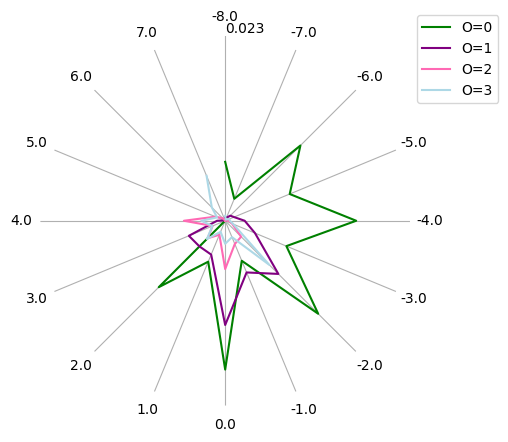

In [8]:
#Generate the delta plot.
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})

# Define specific colors for certain 'O' values
specific_colors = {
    0: 'green', 1: 'purple', 2: 'hotpink',3: 'lightblue'
}

# Define 'O' values to hide
o_to_hide = [4, 5, 6]

for index, row in pivot_delta_abundance.iterrows():
    o = index

    # Skip plotting if 'o' is in the list of values to hide
    if o in o_to_hide:
        continue
    frac_abundances = row.values

    # Assign color based on 'o' value from the specific_colors dictionary
    # If 'o' is not in specific_colors, use a default color (e.g., 'gray')
    color = specific_colors.get(o, 'gray')

    ax.plot(angles, frac_abundances, label=f'O={o}', color=color)

ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.set_rlabel_position(0)
ax.legend(loc='lower left', bbox_to_anchor=(1, 0.8))

max_abundance = delta_abundance['frac_abundance'].max()
max_abudance_rounded = round(max_abundance, 3)+0.2*round(max_abundance, 2)
ax.set_rmax(max_abudance_rounded)
ax.set_rmin(0.0)
#print(max_abudance_rounded)

ax.set_xticks(angles)
ax.set_xticklabels(delta_values)
ax.set_yticks([ax.get_rmax()])

# Remove circular radial lines by explicitly turning off the y-axis grid
ax.yaxis.grid(False)

# Make the outer ring (polar spine) transparent
ax.spines['polar'].set_color('none')

plt.show()
fig.savefig('260505_VL+UV+seeds_85RH.jpg')